In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [3]:
!pip install -q notebook-llm-cli

In [4]:
import notebook_llm
notebook_llm.run()


== notebook_llm ==
  2x Tesla T4 | 30.0 GB VRAM | 30 GB RAM | 4 CPU cores
  VRAM in use: 0.9 / 30.0 GB
  Disk   : 967 GB free  (/root/.ollama/models)
  Server : stopped
  Model  : (none selected)
  Tunnel : closed

  1) Quick start (auto: install, model, tunnel)
  2) Search Ollama library
  3) Recommended models for my GPU
  4) Quant picker (compare q4 / q5 / q8 / fp16)
  5) Installed models (load / benchmark / delete)
  6) Connect your tools (Cline, Aider, Cursor, Claude Code...)
  7) Tunnel (open / get link / close)
  8) Server (start / stop / logs)
  9) Settings (context, KV cache, keep-alive, folder)
  10) Benchmark active model
  0) Quit (server and tunnel keep running)


> Choose:  2


  Search ollama.com/search. Examples:  coder   |   /vision   |   qwen /tools   |   /newest
  Filters: /tools /vision /thinking /embedding /cloud /newest /popular.  Or paste a model like qwen3:8b


> Search (blank = all models):  qwen2.5:3b



  qwen2.5:3b  (exact size 1.8 GB)
  Weights 1.8 GB + KV cache 1.3 GB (ctx 32768) + overhead 1.4 GB = 4.5 GB
  Verdict: FITS   Speed: ~86 tok/s   On GPU: 100% of weights

  1) Pull + load now (make it the active model)
  2) Pull only
  Enter) back


> Choose:  1


  Installing/starting Ollama...
[notebook_llm] Installing system packages: zstd, pciutils, lshw
[notebook_llm] Installing Ollama (about 30s)...
Disk check: 964 GB free, need ~3 GB. OK.
  Pulling qwen2.5:3b (1.8 GB)...
  success                                                               
  Loading into VRAM...
OK  qwen2.5:3b is loaded and will stay in memory.


> Open a public tunnel now? (Y/n):  n



== notebook_llm ==
  2x Tesla T4 | 30.0 GB VRAM | 30 GB RAM | 4 CPU cores
  VRAM in use: 4.4 / 30.0 GB
  Disk   : 963 GB free  (/root/.ollama/models)
  Server : running
  Loaded : qwen2.5:3b (3.3 GB, 100% on GPU)
  Model  : qwen2.5:3b
  Tunnel : closed

  1) Quick start (auto: install, model, tunnel)
  2) Search Ollama library
  3) Recommended models for my GPU
  4) Quant picker (compare q4 / q5 / q8 / fp16)
  5) Installed models (load / benchmark / delete)
  6) Connect your tools (Cline, Aider, Cursor, Claude Code...)
  7) Tunnel (open / get link / close)
  8) Server (start / stop / logs)
  9) Settings (context, KV cache, keep-alive, folder)
  10) Benchmark active model
  0) Quit (server and tunnel keep running)


> Choose:  0


In [9]:
import os
import pandas as pd
import kagglehub

dataset_path = kagglehub.dataset_download("rmisra/news-headlines-dataset-for-sarcasm-detection")
file_path = os.path.join(dataset_path, "Sarcasm_Headlines_Dataset.json")

df = pd.read_json(file_path, lines=True)
sarcastic_headlines = df[df['is_sarcastic'] == 1]['headline'].tolist()

test_headlines = sarcastic_headlines[:500]
print(f"Dataset loaded. Total headlines ready for generation: {len(test_headlines)}")

Dataset loaded. Total headlines ready for generation: 500


In [10]:
import time
import pandas as pd
from notebook_llm import NotebookLLM

llm_x = NotebookLLM()
results = []

print("Starting Generation with LLM_X...")

for i, headline in enumerate(test_headlines):
    prompt = f"""
    You are a headline rewriter. Given a sarcastic news headline, write a NEW sarcastic headline.
    Rules:
    - Keep the same sarcastic target.
    - Use DIFFERENT words and sentence structure.
    - Output only the new headline.
    Original: "{headline}"
    New:
    """
    try:
        generated = llm_x.chat(prompt).replace('"', '').strip()
    except Exception as e:
        generated = "Error"
        
    results.append({"Original": headline, "Generated": generated})
    
    if (i+1) % 100 == 0:
        print(f"[{i+1}/500] Generated...")
    time.sleep(0.1)

pd.DataFrame(results).to_csv("generated_500_headlines.csv", index=False)
print("Generation Complete! Saved to 'generated_500_headlines.csv'")

Starting Generation with LLM_X...
[100/500] Generated...
[200/500] Generated...
[300/500] Generated...
[400/500] Generated...
[500/500] Generated...
Generation Complete! Saved to 'generated_500_headlines.csv'


In [11]:
import time
import pandas as pd
from notebook_llm import NotebookLLM

# Load the generated headlines
df = pd.read_csv("generated_500_headlines.csv")

# Initialize LLM_Y (assuming Llama is running in the background)
llm_y = NotebookLLM()
print("Starting Evaluation with LLM_Y...")

for i, row in df.iterrows():
    eval_prompt = f"""
    Original: "{row['Original']}"
    Generated: "{row['Generated']}"
    Task: Does the generated headline preserve the sarcastic intent? 
    Answer strictly with 'Sarcastic' or 'Non-Sarcastic'.
    """
    try:
        pred = llm_y.chat(eval_prompt).strip()
    except:
        pred = "Error"
        
    df.at[i, 'LLM_Y_Prediction'] = pred
    
    if (i+1) % 100 == 0:
        print(f"[{i+1}/500] Evaluated by LLM_Y...")
    time.sleep(0.1)

df.to_csv("evaluation_500_Y.csv", index=False)
print("LLM_Y Evaluation Complete! Saved to 'evaluation_500_Y.csv'")

Starting Evaluation with LLM_Y...
[100/500] Evaluated by LLM_Y...
[200/500] Evaluated by LLM_Y...
[300/500] Evaluated by LLM_Y...
[400/500] Evaluated by LLM_Y...
[500/500] Evaluated by LLM_Y...
LLM_Y Evaluation Complete! Saved to 'evaluation_500_Y.csv'


In [12]:
import time
import pandas as pd
from notebook_llm import NotebookLLM

# Load the file that already has LLM_Y predictions
df = pd.read_csv("evaluation_500_Y.csv")

# Initialize LLM_Z (assuming Gemma is running in the background)
llm_z = NotebookLLM()
print("Starting Evaluation with LLM_Z...")

for i, row in df.iterrows():
    eval_prompt = f"""
    Original: "{row['Original']}"
    Generated: "{row['Generated']}"
    Task: Does the generated headline preserve the sarcastic intent? 
    Answer strictly with 'Sarcastic' or 'Non-Sarcastic'.
    """
    try:
        pred = llm_z.chat(eval_prompt).strip()
    except:
        pred = "Error"
        
    df.at[i, 'LLM_Z_Prediction'] = pred
    
    if (i+1) % 100 == 0:
        print(f"[{i+1}/500] Evaluated by LLM_Z...")
    time.sleep(0.1)

# Jaccard Similarity Calculation
def jaccard_similarity(str1, str2):
    a, b = set(str1.lower().split()), set(str2.lower().split())
    return float(len(a & b)) / (len(a) + len(b) - len(a & b))

df['Jaccard'] = df.apply(lambda row: jaccard_similarity(row['Original'], row['Generated']), axis=1)
df.to_csv("final_500_master_file.csv", index=False)

# Print Final Metrics
agreement = (df['LLM_Y_Prediction'] == df['LLM_Z_Prediction']).mean() * 100
both_sarcastic = ((df['LLM_Y_Prediction'] == 'Sarcastic') & (df['LLM_Z_Prediction'] == 'Sarcastic')).sum()
avg_jaccard = df['Jaccard'].mean()

print("\n--- Final Verified Results ---")
print(f"Inter-Model Agreement: {agreement:.2f}%") 
print(f"Both Classified as Sarcastic: {both_sarcastic} / 500")
print(f"Average Jaccard Similarity: {avg_jaccard:.4f}")

Starting Evaluation with LLM_Z...
[100/500] Evaluated by LLM_Z...
[200/500] Evaluated by LLM_Z...
[300/500] Evaluated by LLM_Z...
[400/500] Evaluated by LLM_Z...
[500/500] Evaluated by LLM_Z...

--- Final Verified Results ---
Inter-Model Agreement: 95.40%
Both Classified as Sarcastic: 438 / 500
Average Jaccard Similarity: 0.1474


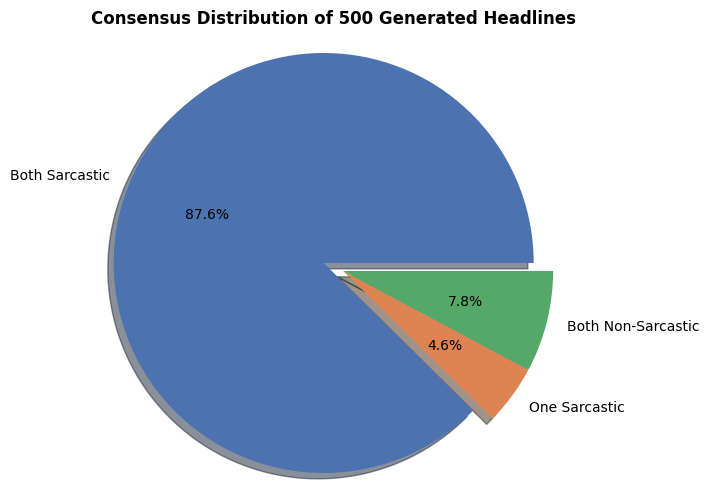

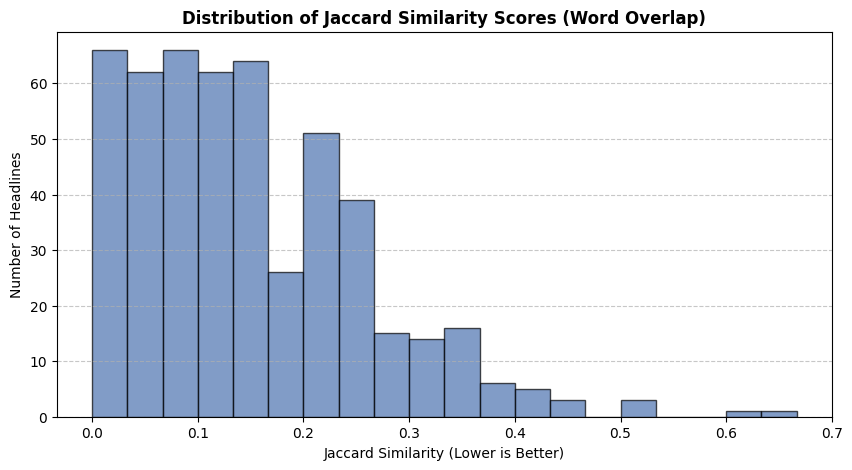

In [13]:
# Cell 5: Data Visualization
import pandas as pd
import matplotlib.pyplot as plt

# Load the final data
df = pd.read_csv("final_500_master_file.csv")

# Pie Chart Data
both = ((df['LLM_Y_Prediction'] == 'Sarcastic') & (df['LLM_Z_Prediction'] == 'Sarcastic')).sum()
one = (df['LLM_Y_Prediction'] != df['LLM_Z_Prediction']).sum()
none = len(df) - both - one

plt.figure(figsize=(8, 6))
plt.pie([both, one, none], labels=['Both Sarcastic', 'One Sarcastic', 'Both Non-Sarcastic'], 
        colors=['#4C72B0', '#DD8452', '#55A868'], autopct='%1.1f%%', shadow=True, explode=(0.1, 0, 0))
plt.title('Consensus Distribution of 500 Generated Headlines', fontweight='bold')
plt.axis('equal')
plt.savefig('pie_chart.png', dpi=300, bbox_inches='tight')
plt.show()

# Histogram
plt.figure(figsize=(10, 5))
plt.hist(df['Jaccard'], bins=20, color='#4C72B0', edgecolor='black', alpha=0.7)
plt.title('Distribution of Jaccard Similarity Scores (Word Overlap)', fontweight='bold')
plt.xlabel('Jaccard Similarity (Lower is Better)')
plt.ylabel('Number of Headlines')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig('jaccard_hist.png', dpi=300, bbox_inches='tight')
plt.show()